In [2]:
import torch
import numpy as np
import pandas as pd
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import random
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report, roc_curve

from data_setup import TESSDataset, create_dataloaders
from torch.utils.data import DataLoader

In [ ]:
RANDOM_SEED = 42

def set_seed(seed: int = 42):
    # REPRODUCIBILITY
    
    random.seed(seed)
    
    os.environ['PYTHONHASHSEED'] = str(seed)
    
    np.random.seed(seed)
    
    torch.manual_seed(seed)
    
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)
        
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

In [4]:
device = "mps" if torch.backends.mps.is_available() else "cpu"

if device == 'mps':
    torch.mps.manual_seed(RANDOM_SEED)

device

'mps'

In [5]:
csv_path = "data/processed_labels_v3.csv"
data_dir = "data/lightcurves_v2"
BATCH_SIZE = 32

In [6]:
def accuracy_fn(y_true, y_pred):
    y_pred_rounded = torch.round(y_pred)
    
    y_true_int = y_true.cpu().int()
    y_pred_int = y_pred_rounded.cpu().int()
    
    correct = torch.eq(y_true_int, y_pred_int).sum().item() 
    
    acc = (correct / len(y_pred)) * 100 
    return acc

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class TESSModelV5Aux(nn.Module):
    def __init__(self, n_aux_features = 1):
        super().__init__()
        
        self.aux_branch = nn.Sequential(
            nn.Linear(n_aux_features, 16),
            nn.ReLU(),
        )

        self.global_view = nn.Sequential(
            nn.Conv1d(
                in_channels = 1,
                out_channels = 16,
                kernel_size = 61,
                stride = 4,
                #padding = 30
            ),
            nn.BatchNorm1d(16),
            nn.LeakyReLU(0.1),
            nn.Dropout1d(p = 0.2),
            nn.MaxPool1d(kernel_size = 4),
            nn.Conv1d(
                in_channels = 16,
                out_channels = 32,
                kernel_size = 31,
                stride = 2,
                padding = 15
            ),
            nn.BatchNorm1d(32),
            nn.LeakyReLU(0.1),
            nn.Dropout1d(p = 0.2),
            nn.MaxPool1d(kernel_size = 4)
        )

        self.focused_view = nn.Sequential(
            nn.Conv1d(
                in_channels = 1,
                out_channels = 16,
                kernel_size = 5,
                stride = 2,
                #padding = 10
            ),
            nn.BatchNorm1d(16),
            nn.LeakyReLU(0.1),
            nn.Dropout1d(p = 0.2),
            nn.MaxPool1d(kernel_size = 2),
            nn.Conv1d(
                in_channels = 16,
                out_channels = 32,
                kernel_size = 5,
                stride = 1,
                #padding = 3
            ), 
            nn.BatchNorm1d(32),
            nn.LeakyReLU(0.1),
            nn.Dropout1d(p = 0.2),
            nn.MaxPool1d(kernel_size = 2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features = 128 + 16, out_features = 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.1),
            nn.Dropout(p = 0.5), 
            nn.Linear(in_features = 128, out_features = 1)
        )

    def pool_branch(self, feat):
        avg = F.adaptive_avg_pool1d(feat, 1).squeeze(-1)
        mn = -F.adaptive_max_pool1d(-feat, 1).squeeze(-1)
        return torch.cat([avg, mn], dim = 1)
        
    def forward(self, x, aux):
        x_focused = x[:, :, 9000:11000]

        global_output = self.global_view(x)
        focused_output = self.focused_view(x_focused)

        global_summary  = self.pool_branch(global_output)
        focused_summary = self.pool_branch(focused_output)
        
        merge_views = torch.cat([global_summary, focused_summary], dim = 1)

        aux_out = self.aux_branch(aux)

        return self.classifier(torch.cat([merge_views, aux_out], dim = 1))

In [8]:
train_dataloader, test_dataloader = create_dataloaders(
    csv_path = csv_path,
    data_dir = data_dir,
    batch_size = BATCH_SIZE,
    aux_cols = ["aux_log_period", "aux_log_depth", "aux_log_duration", "aux_teff", "aux_log_rs", "aux_log_rp", "aux_log_dur_ratio", "aux_rs_missing"]
)

print((~np.isfinite(train_dataloader.dataset.labels_df["log_period"])).sum())

Dataset initialized with 1784 strictly synced samples.
Dataset initialized with 447 strictly synced samples.
0


In [8]:
import torch
import torch.optim as optim
import copy

tag = "notag"
results = []
per_seed_reports = []
summed_cm = np.zeros((2, 2), dtype=int)

probs_by_seed = {}
for seed in [1, 2, 3, 4, 5]:
    set_seed(seed)
    train_dataloader, test_dataloader = create_dataloaders(
        csv_path = csv_path,
        data_dir = data_dir,
        batch_size = BATCH_SIZE,
        aux_cols = ["aux_log_period", "aux_log_depth", "aux_log_duration", "aux_teff", "aux_log_rs", "aux_log_rp", "aux_log_dur_ratio", "aux_rs_missing"],
        seed = seed
    )
    
    model_5aux = TESSModelV5Aux(n_aux_features = 8).to(device)
    
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model_5aux.parameters(), lr = 0.001, weight_decay = 1e-4) ##
    
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, 
        mode = 'min', 
        factor = 0.5, 
        patience = 5
    )
    
    epochs = 100
    
    best_test_loss = float('inf')
    best_model_weights = None
    best_epoch = 0
    
    for epoch in range(epochs):
        ### TRAINING
        model_5aux.train() ##
        train_loss, train_accuracy = 0, 0
        
        for X, y, aux in train_dataloader:
            X, y, aux = X.to(device), y.to(device), aux.to(device)
    
            # Z-Score Normalization
            mean = X.mean(dim = 2, keepdim = True)
            std = X.std(dim = 2, keepdim = True)
            X = (X - mean) / (std + 1e-8)
            
            y = y.float().unsqueeze(dim = 1)
            
            y_pred = model_5aux(X, aux) ##
            
            loss = loss_fn(y_pred, y)
            train_loss += loss.item()
    
            y_pred_probs = torch.sigmoid(y_pred)
            train_accuracy += accuracy_fn(y_true = y, y_pred = y_pred_probs)
            
            optimizer.zero_grad()
            
            loss.backward()
            
            optimizer.step()
            
        train_loss /= len(train_dataloader)
        train_accuracy /= len(train_dataloader)
        
        ### TESTING
        model_5aux.eval() ##
        test_loss, test_accuracy = 0, 0
        
        with torch.inference_mode():
            for X_test, y_test, aux_test in test_dataloader:
                X_test, y_test, aux_test = X_test.to(device), y_test.to(device), aux_test.to(device)
    
                mean = X_test.mean(dim = 2, keepdim = True)
                std = X_test.std(dim = 2, keepdim = True)
                X_test = (X_test - mean) / (std + 1e-8)
    
                y_test = y_test.float().unsqueeze(dim = 1)
                
                test_pred = model_5aux(X_test, aux_test) ##
                
                loss = loss_fn(test_pred, y_test)
                test_loss += loss.item()
    
                test_pred_probs = torch.sigmoid(test_pred)
                test_accuracy += accuracy_fn(y_true = y_test, y_pred = test_pred_probs)
                
            test_loss /= len(test_dataloader)
            test_accuracy /= len(test_dataloader)
    
        scheduler.step(test_loss)
        current_lr = optimizer.param_groups[0]['lr']
            
        # Checkpointing implementation
        if test_loss < best_test_loss:
            best_test_loss = test_loss
            best_test_accuracy = test_accuracy
            best_epoch = epoch
            
            best_model_weights = copy.deepcopy(model_5aux.state_dict()) ##
            checkpoint_msg = "|Saved|"
            
        else:
            checkpoint_msg = ""
            
        # Print
        if checkpoint_msg:
            print(f"Epoch {epoch} | LR: {current_lr:.8f} | Train Loss: {train_loss:.4f} Accuracy: {train_accuracy:.2f}% | Test Loss: {test_loss:.4f} Accuracy: {test_accuracy:.2f}% {checkpoint_msg}")
    
    # Load the captured best state of the model
    print(f"Best state captured at Epoch: {best_epoch}, test loss: {best_test_loss:.4f}, test accuracy: {best_test_accuracy:.2f}")
    
    # Overwrite model with captured best state
    model_5aux.load_state_dict(best_model_weights) ##

    torch.save(best_model_weights, f"model_{tag}_seed_{seed}.pt")
    
    results.append({
        "seed": seed,
        "test_acc": best_test_accuracy,
        "test_loss": best_test_loss,
    })

    model_5aux.eval()
    all_true, all_probs = [], []
    with torch.inference_mode():
        for X_test, y_test, aux_test in test_dataloader:
            X_test, aux_test = X_test.to(device), aux_test.to(device)
            mean = X_test.mean(dim=2, keepdim=True); std = X_test.std(dim=2, keepdim=True)
            X_test = (X_test - mean) / (std + 1e-8)
            probs = torch.sigmoid(model_5aux(X_test, aux_test)).squeeze().cpu().numpy()
            all_probs.extend(np.atleast_1d(probs))
            all_true.extend(np.atleast_1d(y_test.squeeze().cpu().numpy()))

    all_true, all_probs = np.array(all_true), np.array(all_probs)
    probs_by_seed[seed] = all_probs.copy()
    np.save(f"cnn_probs_notag_seed{seed}.npy", all_probs)
    fpr, tpr, thresholds = roc_curve(all_true, all_probs)
    opt_threshold = thresholds[np.argmax(tpr - fpr)]
    all_preds = (all_probs >= opt_threshold).astype(int)

    report = classification_report(all_true, all_preds, target_names=['No Planet (0)', 'Planet (1)'], output_dict=True)
    report["seed"] = seed
    per_seed_reports.append(report)
    summed_cm += confusion_matrix(all_true, all_preds)

print(np.allclose(probs_by_seed[1], probs_by_seed[2]))
print(np.max(np.abs(probs_by_seed[1] - probs_by_seed[2])))

results_df = pd.DataFrame(results)
print(results_df)
print(f"Mean accuracy: {results_df['test_acc'].mean():.3f} ± {results_df['test_acc'].std():.3f}")


Dataset initialized with 1784 strictly synced samples.
Dataset initialized with 447 strictly synced samples.
Epoch 0 | LR: 0.00100000 | Train Loss: 0.6887 Accuracy: 56.44% | Test Loss: 0.6596 Accuracy: 62.82% |Saved|
Epoch 1 | LR: 0.00100000 | Train Loss: 0.6565 Accuracy: 62.33% | Test Loss: 0.6447 Accuracy: 64.42% |Saved|
Epoch 2 | LR: 0.00100000 | Train Loss: 0.6315 Accuracy: 63.86% | Test Loss: 0.6303 Accuracy: 65.76% |Saved|
Epoch 3 | LR: 0.00100000 | Train Loss: 0.6308 Accuracy: 64.77% | Test Loss: 0.6275 Accuracy: 66.20% |Saved|
Epoch 4 | LR: 0.00100000 | Train Loss: 0.6117 Accuracy: 66.42% | Test Loss: 0.6204 Accuracy: 68.45% |Saved|
Epoch 5 | LR: 0.00100000 | Train Loss: 0.6067 Accuracy: 66.98% | Test Loss: 0.6156 Accuracy: 68.22% |Saved|
Epoch 6 | LR: 0.00100000 | Train Loss: 0.6027 Accuracy: 67.37% | Test Loss: 0.6049 Accuracy: 68.67% |Saved|
Epoch 8 | LR: 0.00100000 | Train Loss: 0.5909 Accuracy: 68.82% | Test Loss: 0.5915 Accuracy: 70.90% |Saved|
Epoch 9 | LR: 0.00100000 | 

In [ ]:
import numpy as np
print(len(probs_by_seed[1]))      # print 447? = correct
for s, p in probs_by_seed.items():
    np.save(f"cnn_probs_tmag_seed{s}.npy", p)
np.save("test_tic_ids.npy", test_dataloader.dataset.labels_df["TIC_ID"].astype(int).values)

447


Optimal threshold: 0.485
               precision    recall  f1-score   support

No Planet (0)       0.79      0.65      0.71       215
   Planet (1)       0.72      0.84      0.77       232

     accuracy                           0.74       447
    macro avg       0.75      0.74      0.74       447
 weighted avg       0.75      0.74      0.74       447



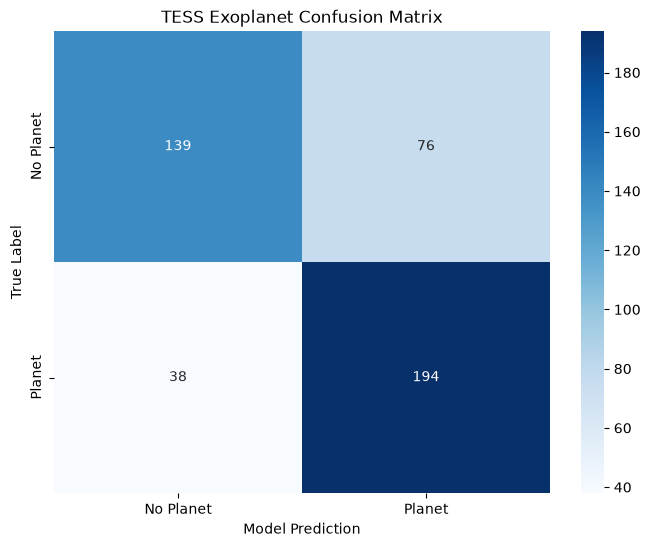

In [10]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

model_5aux = TESSModelV5Aux(n_aux_features = 9).to(device)
model_5aux.load_state_dict(torch.load("model_seed_3.pt"))
model_5aux.eval() ##

all_preds = []
all_true = []
all_probs = []
all_raw_flux = []

with torch.inference_mode():
    for X_test, y_test, aux_test in test_dataloader:
        X_test, aux_test = X_test.to(device), aux_test.to(device)

        all_raw_flux.append(X_test.cpu())

        mean = X_test.mean(dim = 2, keepdim = True)
        std = X_test.std(dim = 2, keepdim = True)
        X_test = (X_test - mean) / (std + 1e-8)
        
        test_logits = model_5aux(X_test, aux_test) ##
        test_probs = torch.sigmoid(test_logits).squeeze().cpu().numpy() 

        if test_probs.ndim == 0:
            all_probs.append(test_probs)
        else:
            all_probs.extend(test_probs)
        
        all_true.extend(y_test.squeeze().cpu().numpy())

all_true = np.array(all_true)
all_probs = np.array(all_probs)
X_test_raw = torch.cat(all_raw_flux)


fpr, tpr, thresholds = roc_curve(all_true, all_probs)
youden_j = tpr - fpr
best_idx = np.argmax(youden_j)
opt_threshold = thresholds[best_idx]
print(f"Optimal threshold: {opt_threshold:.3f}")

all_preds = (all_probs >= opt_threshold).astype(int)

print(classification_report(all_true, all_preds, target_names = ['No Planet (0)', 'Planet (1)']))

cm = confusion_matrix(all_true, all_preds)

plt.figure(figsize = (8, 6))
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues', 
            xticklabels = ['No Planet', 'Planet'],
            yticklabels = ['No Planet', 'Planet'])

plt.title("TESS Exoplanet Confusion Matrix")
plt.ylabel("True Label")
plt.xlabel("Model Prediction")
plt.show()

In [11]:
for r in per_seed_reports:
    print(r["seed"], r["accuracy"])

1 0.738255033557047
2 0.738255033557047
3 0.7449664429530202
4 0.7404921700223713
5 0.7516778523489933


In [12]:
print([id(r) for r in per_seed_reports])

[4745018816, 4672839104, 5186756736, 4678740800, 5186792384]


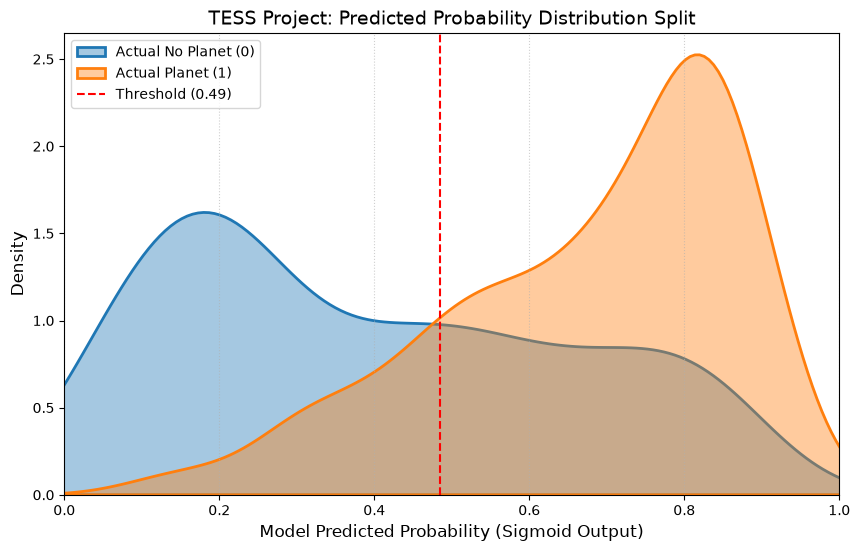

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

probs_arr = np.array(all_probs)
true_arr = np.array(all_true)

plt.figure(figsize=(10, 6))

sns.kdeplot(
    probs_arr[true_arr == 0], 
    label = 'Actual No Planet (0)', 
    fill = True, 
    alpha = 0.4,
    linewidth = 2
)

sns.kdeplot(
    probs_arr[true_arr == 1], 
    label = 'Actual Planet (1)', 
    fill = True, 
    alpha = 0.4,
    linewidth = 2
)

plt.axvline(x = opt_threshold, color = 'red', linestyle = '--', label = f'Threshold ({opt_threshold:.2f})')

plt.title('TESS Project: Predicted Probability Distribution Split', fontsize = 14)
plt.xlabel('Model Predicted Probability (Sigmoid Output)', fontsize = 12)
plt.ylabel('Density', fontsize = 12)
plt.xlim(0, 1)
plt.legend(loc = 'upper left')
plt.grid(axis = 'x', linestyle = ':', alpha = 0.6)
plt.show()

In [ ]:
# DEPTH SHORTCUT CHECK 1
depths = 1.0 - X_test_raw.amin(dim=2).squeeze().cpu().numpy() 
shallow_mask = (true_arr == 1) & (depths < 0.01)
deep_mask    = (true_arr == 1) & (depths >= 0.03)

print("Shallow planets - mean predicted prob:", probs_arr[shallow_mask].mean())
print("Deep planets — mean predicted prob:", probs_arr[deep_mask].mean())

Shallow planets — mean predicted prob: 0.6286106
Deep planets — mean predicted prob: 0.72972083


In [ ]:
# DEPTH SHORTCUT CHECK 2
shallow_np_mask = (true_arr == 0) & (depths < 0.01)
deep_np_mask    = (true_arr == 0) & (depths >= 0.03)

print("Shallow No-Planet — mean predicted prob:", probs_arr[shallow_np_mask].mean())
print("Deep No-Planet — mean predicted prob:", probs_arr[deep_np_mask].mean())

Shallow No-Planet — mean predicted prob: 0.30051476
Deep No-Planet — mean predicted prob: 0.51707405


In [16]:
for seed in [1, 2, 3, 4, 5]:
    model_5aux = TESSModelV5Aux(n_aux_features = 9).to(device)
    model_5aux.load_state_dict(torch.load(f"model_seed_{seed}.pt"))
    model_5aux.eval()

    all_true = []
    all_probs = []
    all_raw_flux = []

    with torch.inference_mode():
        for X_test, y_test, aux_test in test_dataloader:
            X_test, aux_test = X_test.to(device), aux_test.to(device)
            all_raw_flux.append(X_test.cpu())

            mean = X_test.mean(dim=2, keepdim=True)
            std = X_test.std(dim=2, keepdim=True)
            X_test = (X_test - mean) / (std + 1e-8)

            test_logits = model_5aux(X_test, aux_test)
            test_probs = torch.sigmoid(test_logits).squeeze().cpu().numpy()
            all_probs.extend(np.atleast_1d(test_probs))
            all_true.extend(np.atleast_1d(y_test.squeeze().cpu().numpy()))

    all_true = np.array(all_true)
    all_probs = np.array(all_probs)
    X_test_raw = torch.cat(all_raw_flux)

    depths = 1.0 - X_test_raw.amin(dim=2).squeeze().cpu().numpy()
    shallow_mask = (all_true == 1) & (depths < 0.01)
    deep_mask    = (all_true == 1) & (depths >= 0.03)
    shallow_np_mask = (all_true == 0) & (depths < 0.01)
    deep_np_mask    = (all_true == 0) & (depths >= 0.03)

    planet_gap = all_probs[deep_mask].mean() - all_probs[shallow_mask].mean()
    no_planet_gap = all_probs[deep_np_mask].mean() - all_probs[shallow_np_mask].mean()

    print(f"Seed {seed}: Planet gap = {planet_gap:.4f}, No-Planet gap = {no_planet_gap:.4f}")

Seed 1: Planet gap = 0.0989, No-Planet gap = 0.1817
Seed 2: Planet gap = 0.1109, No-Planet gap = 0.1760
Seed 3: Planet gap = 0.1011, No-Planet gap = 0.2166
Seed 4: Planet gap = 0.0962, No-Planet gap = 0.1662
Seed 5: Planet gap = 0.1167, No-Planet gap = 0.1549


In [9]:
from run_protocol import run_protocol

# no Tmag
res_notag = run_protocol(
    csv_path, data_dir,
    aux_cols=["aux_log_period", "aux_log_depth", "aux_log_duration", "aux_teff",
              "aux_log_rs", "aux_log_rp", "aux_log_dur_ratio", "aux_rs_missing"],
    model_fn=lambda n: TESSModelV5Aux(n_aux_features=n),
    device=device, set_seed=set_seed, tag="notag_val")

train 1561 | val 223 | test 447
Dataset initialized with 223 strictly synced samples.
Dataset initialized with 447 strictly synced samples.
Dataset initialized with 1561 strictly synced samples.
{'seed': 1, 'best_epoch': 97, 'val_loss': 0.52, 'val_acc': 76.233, 'test_loss': 0.524, 'test_acc_0p5': 72.036, 'thr_from_val': 0.586, 'test_acc_val_thr': 71.365}
Dataset initialized with 1561 strictly synced samples.
{'seed': 2, 'best_epoch': 86, 'val_loss': 0.53, 'val_acc': 75.336, 'test_loss': 0.548, 'test_acc_0p5': 70.246, 'thr_from_val': 0.486, 'test_acc_val_thr': 70.47}
Dataset initialized with 1561 strictly synced samples.
{'seed': 3, 'best_epoch': 99, 'val_loss': 0.512, 'val_acc': 77.13, 'test_loss': 0.527, 'test_acc_0p5': 72.707, 'thr_from_val': 0.548, 'test_acc_val_thr': 70.694}
Dataset initialized with 1561 strictly synced samples.
{'seed': 4, 'best_epoch': 83, 'val_loss': 0.51, 'val_acc': 75.336, 'test_loss': 0.525, 'test_acc_0p5': 73.826, 'thr_from_val': 0.579, 'test_acc_val_thr': 7

In [10]:
from run_protocol import run_protocol

# no Tmag
res_tmag = run_protocol(
    csv_path, data_dir,
    aux_cols=["aux_log_period", "aux_log_depth", "aux_log_duration", "aux_teff",
              "aux_log_rs", "aux_log_rp", "aux_log_dur_ratio", "aux_rs_missing", "aux_tmag"],
    model_fn=lambda n: TESSModelV5Aux(n_aux_features=n),
    device=device, set_seed=set_seed, tag="tmag_val")

train 1561 | val 223 | test 447
Dataset initialized with 223 strictly synced samples.
Dataset initialized with 447 strictly synced samples.
Dataset initialized with 1561 strictly synced samples.
{'seed': 1, 'best_epoch': 97, 'val_loss': 0.542, 'val_acc': 73.094, 'test_loss': 0.553, 'test_acc_0p5': 69.799, 'thr_from_val': 0.441, 'test_acc_val_thr': 70.47}
Dataset initialized with 1561 strictly synced samples.
{'seed': 2, 'best_epoch': 87, 'val_loss': 0.51, 'val_acc': 76.233, 'test_loss': 0.536, 'test_acc_0p5': 73.154, 'thr_from_val': 0.461, 'test_acc_val_thr': 72.707}
Dataset initialized with 1561 strictly synced samples.
{'seed': 3, 'best_epoch': 97, 'val_loss': 0.505, 'val_acc': 73.094, 'test_loss': 0.551, 'test_acc_0p5': 71.365, 'thr_from_val': 0.403, 'test_acc_val_thr': 70.917}
Dataset initialized with 1561 strictly synced samples.
{'seed': 4, 'best_epoch': 93, 'val_loss': 0.512, 'val_acc': 73.991, 'test_loss': 0.54, 'test_acc_0p5': 72.036, 'thr_from_val': 0.454, 'test_acc_val_thr':

In [11]:
from run_protocol import run_protocol

# no Tmag
res_base = run_protocol(
    csv_path, data_dir,
    aux_cols=["aux_log_period", "aux_log_depth"],
    model_fn=lambda n: TESSModelV5Aux(n_aux_features=n),
    device=device, set_seed=set_seed, tag="base_val")

train 1561 | val 223 | test 447
Dataset initialized with 223 strictly synced samples.
Dataset initialized with 447 strictly synced samples.
Dataset initialized with 1561 strictly synced samples.
{'seed': 1, 'best_epoch': 77, 'val_loss': 0.618, 'val_acc': 65.919, 'test_loss': 0.589, 'test_acc_0p5': 70.246, 'thr_from_val': 0.622, 'test_acc_val_thr': 66.89}
Dataset initialized with 1561 strictly synced samples.
{'seed': 2, 'best_epoch': 68, 'val_loss': 0.614, 'val_acc': 65.471, 'test_loss': 0.595, 'test_acc_0p5': 67.562, 'thr_from_val': 0.573, 'test_acc_val_thr': 66.443}
Dataset initialized with 1561 strictly synced samples.
{'seed': 3, 'best_epoch': 88, 'val_loss': 0.615, 'val_acc': 65.919, 'test_loss': 0.584, 'test_acc_0p5': 68.904, 'thr_from_val': 0.584, 'test_acc_val_thr': 67.785}
Dataset initialized with 1561 strictly synced samples.
{'seed': 4, 'best_epoch': 97, 'val_loss': 0.617, 'val_acc': 65.471, 'test_loss': 0.579, 'test_acc_0p5': 70.022, 'thr_from_val': 0.611, 'test_acc_val_thr